In [2]:
# ==========================================
# PART 1: LOAD THE WATER QUALITY DATASET
# ==========================================

from pathlib import Path
import pandas as pd
import zipfile

# Expected dataset location in the GitHub project
DATA_PATH = Path("data") / "water_dataX.csv"

# If the dataset is not found, allow manual upload in Google Colab
if not DATA_PATH.exists():
    from google.colab import files

    print("Dataset not found in the project folder.")
    print("Please upload water_dataX.csv or water_dataX.csv.zip")

    uploaded = files.upload()

    # Check if a ZIP file was uploaded and unzip it
    zip_files = [name for name in uploaded if name.lower().endswith(".zip")]
    if zip_files:
        print(f"Extracting {zip_files[0]}...")
        with zipfile.ZipFile(zip_files[0], 'r') as zip_ref:
            zip_ref.extractall(".")

    csv_files = [
        name for name in uploaded
        if name.lower().endswith(".csv")
    ]

    # If we extracted a ZIP, look for CSVs in current directory again
    if not csv_files:
        csv_files = list(Path(".").glob("*.csv"))

    if not csv_files:
        raise FileNotFoundError("Please upload a CSV dataset or a ZIP containing one.")

    DATA_PATH = Path(csv_files[0])

# Load dataset
df = pd.read_csv(DATA_PATH, encoding="latin1")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display first five rows
df.head()

Dataset not found in the project folder.
Please upload water_dataX.csv or water_dataX.csv.zip


Saving water_dataX.csv.zip to water_dataX.csv (1).zip
Extracting water_dataX.csv (1).zip...
Dataset loaded successfully!
Dataset shape: (1991, 12)


,STATION CODE,LOCATIONS,STATE,Temp,D.O. (mg/l),PH,CONDUCTIVITY (µmhos/cm),B.O.D. (mg/l),NITRATENAN N+ NITRITENANN (mg/l),FECAL COLIFORM (MPN/100ml),TOTAL COLIFORM (MPN/100ml)Mean,year
0,1393,"DAMANGANGA AT D/S OF MADHUBAN, DAMAN",DAMAN & DIU,30.6,6.7,7.5,203,NAN,0.1,11,27,2014
1,1399,ZUARI AT D/S OF PT. WHERE KUMBARJRIA CANAL JOI...,GOA,29.8,5.7,7.2,189,2,0.2,4953,8391,2014
2,1475,ZUARI AT PANCHAWADI,GOA,29.5,6.3,6.9,179,1.7,0.1,3243,5330,2014
3,3181,RIVER ZUARI AT BORIM BRIDGE,GOA,29.7,5.8,6.9,64,3.8,0.5,5382,8443,2014
4,3182,RIVER ZUARI AT MARCAIM JETTY,GOA,29.5,5.8,7.3,83,1.9,0.4,3428,5500,2014


In [ ]:
# ======================================================
# PART 2: EXPLORE THE DATASET (Simple)
# ======================================================

# 2.1 Look at column names
print("📋 COLUMN NAMES:")
for i, col in enumerate(df.columns):
    print(f"{i+1}. {col}")

# 2.2 Check what's in each column
print("\n" + "="*50)
print("🔍 FIRST FEW ROWS")
print("="*50)
print(df.head())

# 2.3 Basic info about data types
print("\n" + "="*50)
print("📊 DATA TYPES")
print("="*50)
print(df.dtypes)

# 2.4 Check for missing values
print("\n" + "="*50)
print("❓ MISSING VALUES")
print("="*50)
print(df.isnull().sum())

# 2.5 Simple statistics
print("\n" + "="*50)
print("📈 BASIC STATISTICS")
print("="*50)
print(df.describe())

📋 COLUMN NAMES:
1. STATION CODE
2. LOCATIONS
3. STATE
4. Temp
5. D.O. (mg/l)
6. PH
7. CONDUCTIVITY (?mhos/cm)
8. B.O.D. (mg/l)
9. NITRATENAN N+ NITRITENANN (mg/l)
10. FECAL COLIFORM (MPN/100ml)
11. TOTAL COLIFORM (MPN/100ml)Mean
12. year

🔍 FIRST FEW ROWS
  STATION CODE                                          LOCATIONS  \
0         1393               DAMANGANGA AT D/S OF MADHUBAN, DAMAN   
1         1399  ZUARI AT D/S OF PT. WHERE KUMBARJRIA CANAL JOI...   
2         1475                                ZUARI AT PANCHAWADI   
3         3181                        RIVER ZUARI AT BORIM BRIDGE   
4         3182                       RIVER ZUARI AT MARCAIM JETTY   

         STATE  Temp D.O. (mg/l)   PH CONDUCTIVITY (?mhos/cm) B.O.D. (mg/l)  \
0  DAMAN & DIU  30.6         6.7  7.5                     203           NAN   
1          GOA  29.8         5.7  7.2                     189             2   
2          GOA  29.5         6.3  6.9                     179           1.7   
3          GO

In [3]:

# Check dataset structure

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Column names:
['STATION CODE', 'LOCATIONS', 'STATE', 'Temp', 'D.O. (mg/l)', 'PH', 'CONDUCTIVITY (µmhos/cm)', 'B.O.D. (mg/l)', 'NITRATENAN N+ NITRITENANN (mg/l)', 'FECAL COLIFORM (MPN/100ml)', 'TOTAL COLIFORM (MPN/100ml)Mean', 'year']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1991 entries, 0 to 1990
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype 
---  ------                            --------------  ----- 
 0   STATION CODE                      1991 non-null   object
 1   LOCATIONS                         1991 non-null   object
 2   STATE                             1991 non-null   object
 3   Temp                              1991 non-null   object
 4   D.O. (mg/l)                       1991 non-null   object
 5   PH                                1991 non-null   object
 6   CONDUCTIVITY (µmhos/cm)           1991 non-null   object
 7   B.O.D. (mg/l)                     1991 non-null   object
 8   NITRATENAN N

In [ ]:
# ======================================================
# PART 3: DATA CLEANING (Simple)
# ======================================================

# 3.1 Make a copy so original is safe
df_clean = df.copy()

# 3.2 Handle missing values - fill with column average
print("🔧 FILLING MISSING VALUES...")
for col in df_clean.columns:
    if df_clean[col].isnull().sum() > 0:
        # For numbers, fill with average
        if df_clean[col].dtype in ['int64', 'float64']:
            avg = df_clean[col].mean()
            df_clean[col].fillna(avg, inplace=True)
            print(f"  • {col}: filled {df[col].isnull().sum()} missing with average ({avg:.2f})")
        # For text, fill with most common value
        else:
            common = df_clean[col].mode()[0]
            df_clean[col].fillna(common, inplace=True)
            print(f"  • {col}: filled missing with '{common}'")

# 3.3 Check if any missing values remain
print("\n✅ MISSING VALUES AFTER CLEANING:")
print(df_clean.isnull().sum().sum())  # Should be 0

# 3.4 Remove any duplicate rows
initial_rows = len(df_clean)
df_clean.drop_duplicates(inplace=True)
final_rows = len(df_clean)
print(f"\n🔄 Removed {initial_rows - final_rows} duplicate rows")

# 3.5 Quick check of cleaned data
print("\n📊 CLEANED DATASET INFO:")
print(f"Final shape: {df_clean.shape}")
print(f"Rows: {df_clean.shape[0]}, Columns: {df_clean.shape[1]}")

# 3.6 Save cleaned version
df_clean.to_csv('water_dataset_cleaned.csv', index=False)
print("\n💾 Saved cleaned data as 'water_dataset_cleaned.csv'")

🔧 FILLING MISSING VALUES...

✅ MISSING VALUES AFTER CLEANING:
0

🔄 Removed 1 duplicate rows

📊 CLEANED DATASET INFO:
Final shape: (1990, 12)
Rows: 1990, Columns: 12

💾 Saved cleaned data as 'water_dataset_cleaned.csv'


In [5]:

import numpy as np
import pandas as pd

# Create a copy so the original data remains unchanged
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Identify columns that should contain numbers
numeric_columns = [
    'Temp',
    'D.O. (mg/l)',
    'PH',
    'CONDUCTIVITY (µmhos/cm)',
    'B.O.D. (mg/l)',
    'NITRATENAN N+ NITRITENANN (mg/l)',
    'FECAL COLIFORM (MPN/100ml)',
    'TOTAL COLIFORM (MPN/100ml)Mean'
]

# Convert text values into numbers
# Invalid values such as "NAN" become actual missing values
for col in numeric_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col].astype(str).str.strip(),
        errors='coerce'
    )

# Check the cleaned dataset
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nUpdated data types:")
print(df_clean.dtypes)

print("\nMissing values after conversion:")
print(df_clean.isnull().sum())

print("\nCleaned dataset preview:")
display(df_clean.head())


Original dataset shape: (1991, 12)
Cleaned dataset shape: (1990, 12)

Updated data types:
STATION CODE                         object
LOCATIONS                            object
STATE                                object
Temp                                float64
D.O. (mg/l)                         float64
PH                                  float64
CONDUCTIVITY (µmhos/cm)             float64
B.O.D. (mg/l)                       float64
NITRATENAN N+ NITRITENANN (mg/l)    float64
FECAL COLIFORM (MPN/100ml)          float64
TOTAL COLIFORM (MPN/100ml)Mean      float64
year                                  int64
dtype: object

Missing values after conversion:
STATION CODE                          0
LOCATIONS                             0
STATE                                 0
Temp                                 91
D.O. (mg/l)                          30
PH                                    7
CONDUCTIVITY (µmhos/cm)              24
B.O.D. (mg/l)                        42
NITRATENAN N+ 

,STATION CODE,LOCATIONS,STATE,Temp,D.O. (mg/l),PH,CONDUCTIVITY (µmhos/cm),B.O.D. (mg/l),NITRATENAN N+ NITRITENANN (mg/l),FECAL COLIFORM (MPN/100ml),TOTAL COLIFORM (MPN/100ml)Mean,year
0,1393,"DAMANGANGA AT D/S OF MADHUBAN, DAMAN",DAMAN & DIU,30.6,6.7,7.5,203.0,NaN,0.1,11.0,27.0,2014
1,1399,ZUARI AT D/S OF PT. WHERE KUMBARJRIA CANAL JOI...,GOA,29.8,5.7,7.2,189.0,2.0,0.2,4953.0,8391.0,2014
2,1475,ZUARI AT PANCHAWADI,GOA,29.5,6.3,6.9,179.0,1.7,0.1,3243.0,5330.0,2014
3,3181,RIVER ZUARI AT BORIM BRIDGE,GOA,29.7,5.8,6.9,64.0,3.8,0.5,5382.0,8443.0,2014
4,3182,RIVER ZUARI AT MARCAIM JETTY,GOA,29.5,5.8,7.3,83.0,1.9,0.4,3428.0,5500.0,2014


In [6]:

# Calculate percentage of missing values in each column
missing_summary = pd.DataFrame({
    'Missing Values': df_clean.isnull().sum(),
    'Missing Percentage': (
        df_clean.isnull().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)

display(missing_summary)

# View some rows where important measurements are missing
display(
    df_clean[
        df_clean[numeric_columns].isnull().any(axis=1)
    ].head(10)
)


,Missing Values,Missing Percentage
FECAL COLIFORM (MPN/100ml),315,15.83
NITRATENAN N+ NITRITENANN (mg/l),224,11.26
TOTAL COLIFORM (MPN/100ml)Mean,131,6.58
Temp,91,4.57
B.O.D. (mg/l),42,2.11
D.O. (mg/l),30,1.51
CONDUCTIVITY (µmhos/cm),24,1.21
PH,7,0.35
STATE,0,0.00
LOCATIONS,0,0.00


,STATION CODE,LOCATIONS,STATE,Temp,D.O. (mg/l),PH,CONDUCTIVITY (µmhos/cm),B.O.D. (mg/l),NITRATENAN N+ NITRITENANN (mg/l),FECAL COLIFORM (MPN/100ml),TOTAL COLIFORM (MPN/100ml)Mean,year
0,1393,"DAMANGANGA AT D/S OF MADHUBAN, DAMAN",DAMAN & DIU,30.6,6.7,7.5,203.0,NaN,0.1,11.0,27.0,2014
40,2676,"MUCHKUNDI RIVER AT WAKED,RATNAGIRI, NEAR M/S ...",MAHARASHTRA,21.4,7.2,7.7,226.0,3.1,0.8,NaN,130.0,2014
49,2199,SAVITRI RIVER AT OVALE VILLAGE.,MAHARASHTRA,28.4,6.7,7.3,9293.0,3.5,1.8,NaN,0.0,2014
50,2701,"SAVITRI RIVER JACKWELL AT UPSA KENDRE, NANGALW...",MAHARASHTRA,28.0,6.8,7.2,170.0,3.1,1.4,NaN,0.0,2014
51,2702,"SAVITRI RIVER AT SHEDAV DOH, MAHAD,RAIGAD",MAHARASHTRA,27.6,6.8,7.3,4175.0,3.3,1.6,NaN,0.0,2014
52,2703,"SAVITRI RIVER AT DADLI BRIDGE, DADLI, MAHAD, R...",MAHARASHTRA,27.9,6.9,7.3,4282.0,3.3,1.6,NaN,0.0,2014
53,2704,"SAVITRI RIVER AT MUTHAVALI VILLAGE, MAHAD, RAI...",MAHARASHTRA,28.1,6.9,7.3,5551.0,3.4,1.7,NaN,0.0,2014
62,2164,VASHISTI RIVER AT U/S OF THREE M PAPER MILLS N...,MAHARASHTRA,23.0,7.1,7.4,176.0,2.7,0.9,NaN,30.0,2014
63,2713,VASHISHTI RIVER AT D/S OF THREE M PAPER MILLS ...,MAHARASHTRA,23.0,7.0,7.4,178.0,2.7,0.9,NaN,40.0,2014
64,2714,VASHISHTI RIVER AT U/S OF POPHALI NEAR KONPHAN...,MAHARASHTRA,23.0,7.2,7.2,180.0,2.7,1.0,NaN,70.0,2014


In [7]:

# Create another copy for missing-value treatment
df_final = df_clean.copy()

# Fill missing numerical measurements using their median
for col in numeric_columns:
    median_value = df_final[col].median()
    df_final[col] = df_final[col].fillna(median_value)

# Verify missing values
print("Missing values after treatment:")
print(df_final.isnull().sum())

print("\nFinal dataset shape:", df_final.shape)

print("\nFinal dataset preview:")
display(df_final.head())


Missing values after treatment:
STATION CODE                        0
LOCATIONS                           0
STATE                               0
Temp                                0
D.O. (mg/l)                         0
PH                                  0
CONDUCTIVITY (µmhos/cm)             0
B.O.D. (mg/l)                       0
NITRATENAN N+ NITRITENANN (mg/l)    0
FECAL COLIFORM (MPN/100ml)          0
TOTAL COLIFORM (MPN/100ml)Mean      0
year                                0
dtype: int64

Final dataset shape: (1990, 12)

Final dataset preview:


,STATION CODE,LOCATIONS,STATE,Temp,D.O. (mg/l),PH,CONDUCTIVITY (µmhos/cm),B.O.D. (mg/l),NITRATENAN N+ NITRITENANN (mg/l),FECAL COLIFORM (MPN/100ml),TOTAL COLIFORM (MPN/100ml)Mean,year
0,1393,"DAMANGANGA AT D/S OF MADHUBAN, DAMAN",DAMAN & DIU,30.6,6.7,7.5,203.0,1.8965,0.1,11.0,27.0,2014
1,1399,ZUARI AT D/S OF PT. WHERE KUMBARJRIA CANAL JOI...,GOA,29.8,5.7,7.2,189.0,2.0000,0.2,4953.0,8391.0,2014
2,1475,ZUARI AT PANCHAWADI,GOA,29.5,6.3,6.9,179.0,1.7000,0.1,3243.0,5330.0,2014
3,3181,RIVER ZUARI AT BORIM BRIDGE,GOA,29.7,5.8,6.9,64.0,3.8000,0.5,5382.0,8443.0,2014
4,3182,RIVER ZUARI AT MARCAIM JETTY,GOA,29.5,5.8,7.3,83.0,1.9000,0.4,3428.0,5500.0,2014


In [8]:

# Statistical summary of water quality parameters

print("STATISTICAL SUMMARY OF WATER QUALITY DATA")

display(df_final[numeric_columns].describe().round(2))


STATISTICAL SUMMARY OF WATER QUALITY DATA


,Temp,D.O. (mg/l),PH,CONDUCTIVITY (µmhos/cm),B.O.D. (mg/l),NITRATENAN N+ NITRITENANN (mg/l),FECAL COLIFORM (MPN/100ml),TOTAL COLIFORM (MPN/100ml)Mean
count,1990.00,1990.00,1990.00,1990.00,1990.00,1990.00,1.990000e+03,1.990000e+03
mean,26.25,6.40,111.72,1767.13,6.83,1.50,3.051790e+05,4.985858e+05
std,3.29,1.32,1875.63,5521.45,29.10,3.87,8.041915e+06,1.375818e+07
min,10.00,0.00,0.00,0.40,0.10,0.00,0.000000e+00,0.000000e+00
25%,25.00,5.93,6.90,79.00,1.20,0.28,4.100000e+01,1.180000e+02
50%,27.00,6.70,7.30,183.00,1.90,0.52,2.210000e+02,4.680000e+02
75%,28.30,7.20,7.70,568.75,3.60,1.20,6.292500e+02,1.698250e+03
max,35.00,11.40,67115.00,65700.00,534.50,108.70,2.725216e+08,5.110909e+08


In [9]:

# Investigate unusual pH readings

print("pH values greater than 14:")
display(
    df_final[df_final['PH'] > 14][
        ['STATION CODE', 'LOCATIONS', 'STATE', 'PH', 'year']
    ].sort_values(by='PH', ascending=False)
)

print("\nHighest 15 pH readings:")
display(
    df_final.nlargest(15, 'PH')[
        ['STATION CODE', 'LOCATIONS', 'STATE', 'PH', 'year']
    ]
)

print("\nNumber of pH values outside the usual 0–14 scale:")
print(((df_final['PH'] < 0) | (df_final['PH'] > 14)).sum())


pH values greater than 14:


,STATION CODE,LOCATIONS,STATE,PH,year
1921,1435,"KOLAK AT RAILWAY BRIDGE NO. 313 VAPI,VALSAD, G...",NAN,67115.0,2003
1975,1456,"RUSHIKULYA AT GANJAM D/S, ORISSA",NAN,28598.0,2003
1950,1570,"HOSDURG, KERALA",NAN,24336.0,2003
1914,1246,"DAMANGANGA AT KACHIGAON D\S (DAMAN),GUJARAT",NAN,21331.0,2003
1949,1569,"THALIPARAMBA, KERALA",NAN,20850.0,2003
...,...,...,...,...,...
1948,1568,"VALAYUM, KERALA",NAN,46.0,2003
1928,1338,"PERIYAR AT SEWAGE DISCHARGE POINT, KERALA",NAN,44.0,2003
1939,1340,"MANIMALA AT KALLOOPARA, KERALA",NAN,42.0,2003
1931,42,"KALLADA AT PANATHOTTUM KADAVU, PUNALOOR, KERALA",NAN,39.0,2003



Highest 15 pH readings:


,STATION CODE,LOCATIONS,STATE,PH,year
1921,1435,"KOLAK AT RAILWAY BRIDGE NO. 313 VAPI,VALSAD, G...",NAN,67115.0,2003
1975,1456,"RUSHIKULYA AT GANJAM D/S, ORISSA",NAN,28598.0,2003
1950,1570,"HOSDURG, KERALA",NAN,24336.0,2003
1914,1246,"DAMANGANGA AT KACHIGAON D\S (DAMAN),GUJARAT",NAN,21331.0,2003
1949,1569,"THALIPARAMBA, KERALA",NAN,20850.0,2003
1922,1434,AMLAKHADI AFTER CONFL. OF W. WATER FROM ANKLES...,NAN,9948.0,2003
1930,21,"CHALIYAR AT KALLAPALLY, KERALA",NAN,9416.0,2003
1953,1573,"IRUPANAM, KERALA",NAN,3384.0,2003
1936,1341,"PAMBA AT KALLOOPARA, KERALA",NAN,1835.0,2003
1919,1148,"AMBIKA AT BILIMORA, GUJARAT",NAN,1708.0,2003



Number of pH values outside the usual 0–14 scale:
89


In [10]:

# Create a separate dataset for analysis
df_analysis = df_final.copy()

# Count invalid pH readings
invalid_ph = (
    (df_analysis['PH'] < 0) |
    (df_analysis['PH'] > 14)
)

print("Invalid pH readings:", invalid_ph.sum())

# Replace invalid pH readings with missing values
df_analysis.loc[invalid_ph, 'PH'] = np.nan

# Calculate median from valid pH readings
valid_ph_median = df_analysis['PH'].median()

# Fill invalid and missing pH values
df_analysis['PH'] = df_analysis['PH'].fillna(valid_ph_median)

print("\nMedian of valid pH readings:", valid_ph_median)
print("Remaining missing pH values:", df_analysis['PH'].isnull().sum())

print("\nUpdated pH statistics:")
print(df_analysis['PH'].describe())


Invalid pH readings: 89

Median of valid pH readings: 7.3
Remaining missing pH values: 0

Updated pH statistics:
count    1990.000000
mean        7.231461
std         0.634353
min         0.000000
25%         6.900000
50%         7.300000
75%         7.600000
max         9.010000
Name: PH, dtype: float64


📊 Numeric columns for visualization:
1. year


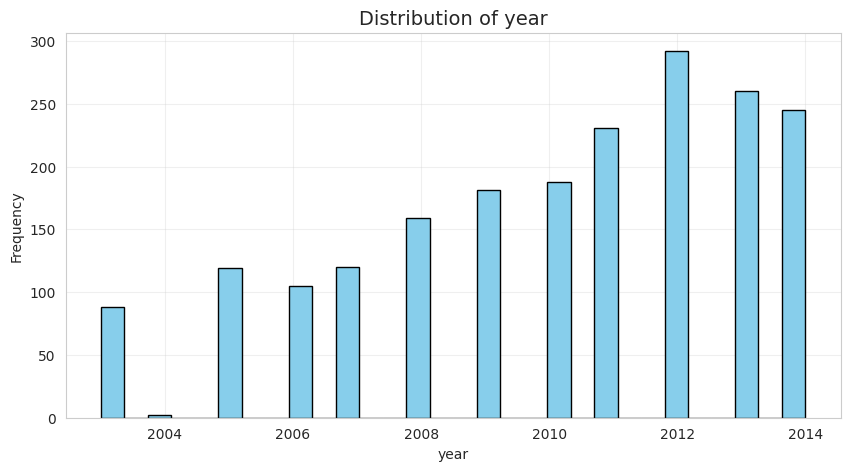

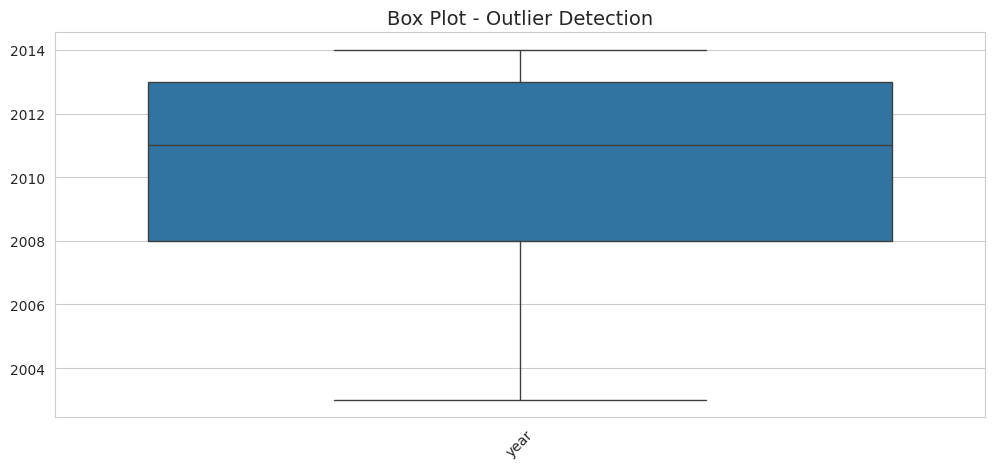

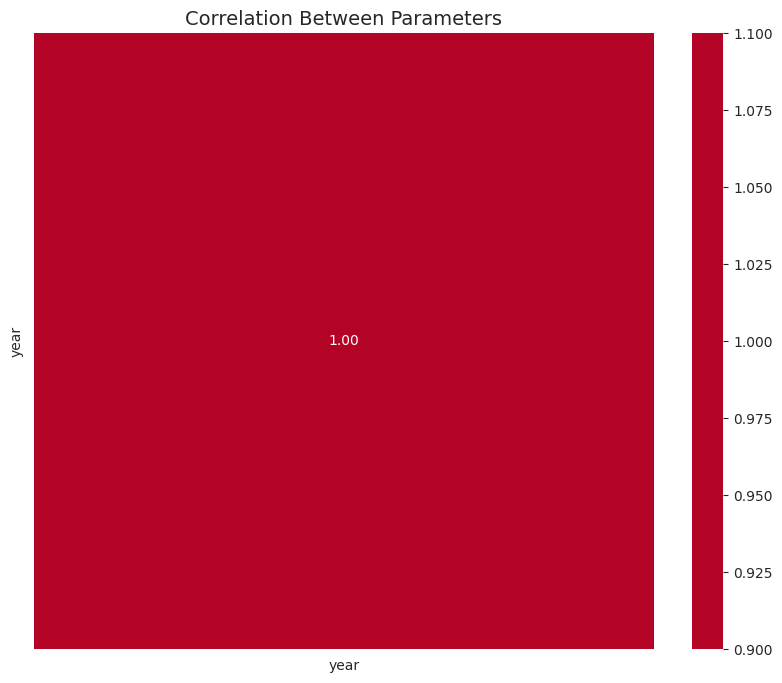

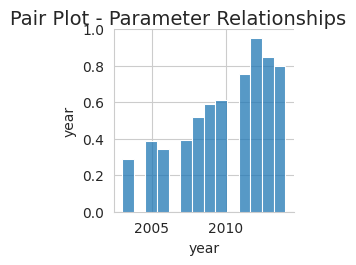

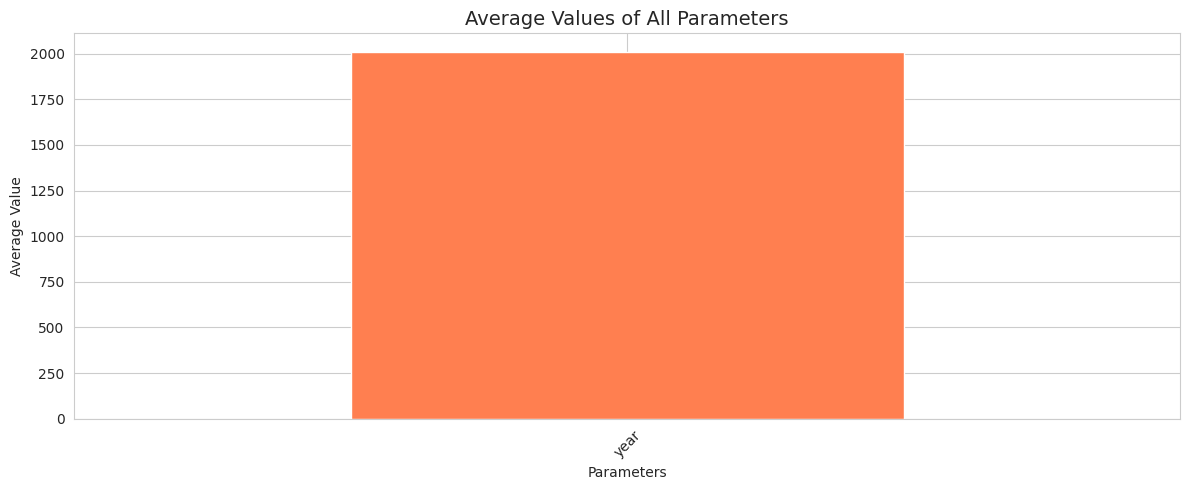

✅ 5 Basic Plots Complete!


In [ ]:
# ======================================================
# PART 4: BASIC VISUALIZATIONS (5 Simple Plots)
# ======================================================

import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# 4.1 First, let's see numeric columns only
numeric_cols = df_clean.select_dtypes(include=['int64', 'float64']).columns
print("📊 Numeric columns for visualization:")
for i, col in enumerate(numeric_cols):
    print(f"{i+1}. {col}")

# ======================================================
# PLOT 1: Distribution of First Numeric Column
# ======================================================
plt.figure(figsize=(10, 5))
first_num = numeric_cols[0]
plt.hist(df_clean[first_num], bins=30, color='skyblue', edgecolor='black')
plt.title(f'Distribution of {first_num}', fontsize=14)
plt.xlabel(first_num)
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)
plt.show()

# ======================================================
# PLOT 2: Box Plot (Shows outliers)
# ======================================================
plt.figure(figsize=(12, 5))
df_box = df_clean[numeric_cols[:4]]  # First 4 numeric columns
sns.boxplot(data=df_box)
plt.title('Box Plot - Outlier Detection', fontsize=14)
plt.xticks(rotation=45)
plt.show()

# ======================================================
# PLOT 3: Correlation Heatmap
# ======================================================
plt.figure(figsize=(10, 8))
correlation = df_clean[numeric_cols].corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation Between Parameters', fontsize=14)
plt.show()

# ======================================================
# PLOT 4: Pair Plot (First 4 columns)
# ======================================================
# Take first 4 numeric columns
first_four = numeric_cols[:4]
sns.pairplot(df_clean[first_four])
plt.suptitle('Pair Plot - Parameter Relationships', y=1.02, fontsize=14)
plt.show()

# ======================================================
# PLOT 5: Line Plot (If there's a time column, else bar chart)
# ======================================================
plt.figure(figsize=(12, 5))
# If you have a year/date column, we'll use it. Otherwise, just show averages
avg_values = df_clean[numeric_cols].mean()
avg_values.plot(kind='bar', color='coral')
plt.title('Average Values of All Parameters', fontsize=14)
plt.xlabel('Parameters')
plt.ylabel('Average Value')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("✅ 5 Basic Plots Complete!")

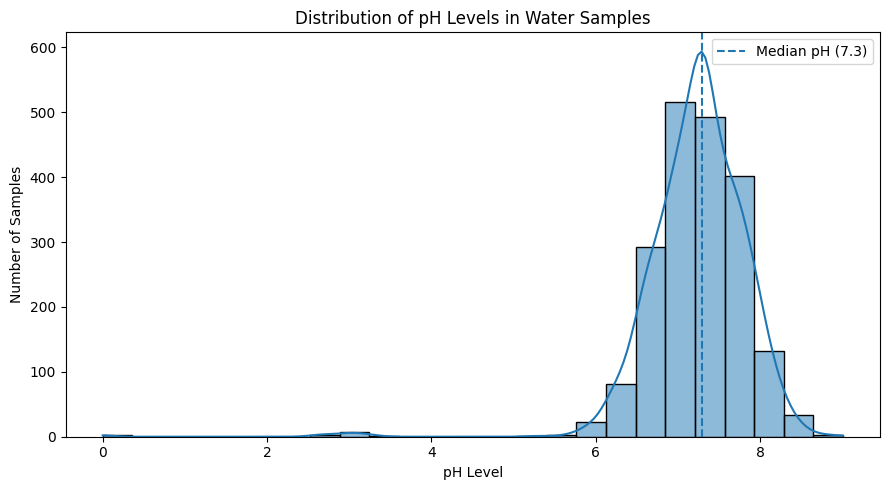

In [11]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_analysis,
    x='PH',
    bins=25,
    kde=True
)

plt.title('Distribution of pH Levels in Water Samples')
plt.xlabel('pH Level')
plt.ylabel('Number of Samples')
plt.axvline(
    df_analysis['PH'].median(),
    linestyle='--',
    label='Median pH (7.3)'
)

plt.legend()
plt.tight_layout()
plt.show()


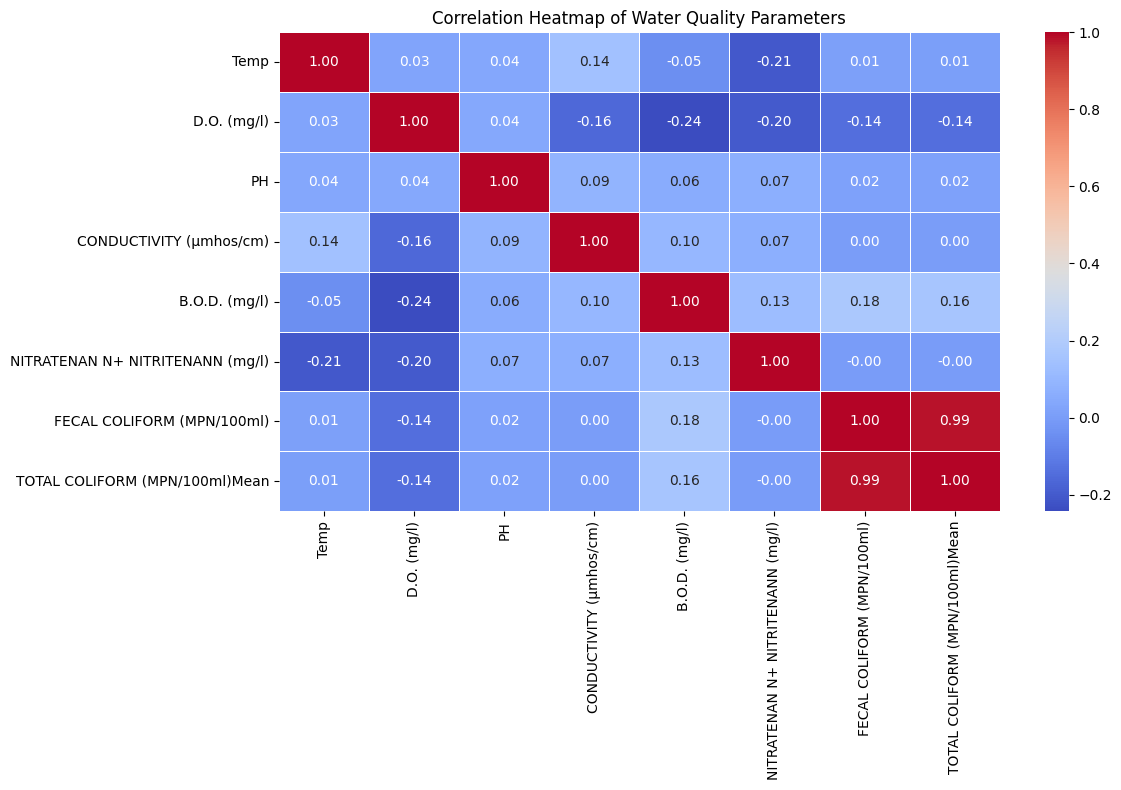

In [12]:

# Correlation analysis
correlation_matrix = df_analysis[numeric_columns].corr()

# Visualise correlations
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Water Quality Parameters')
plt.tight_layout()
plt.show()


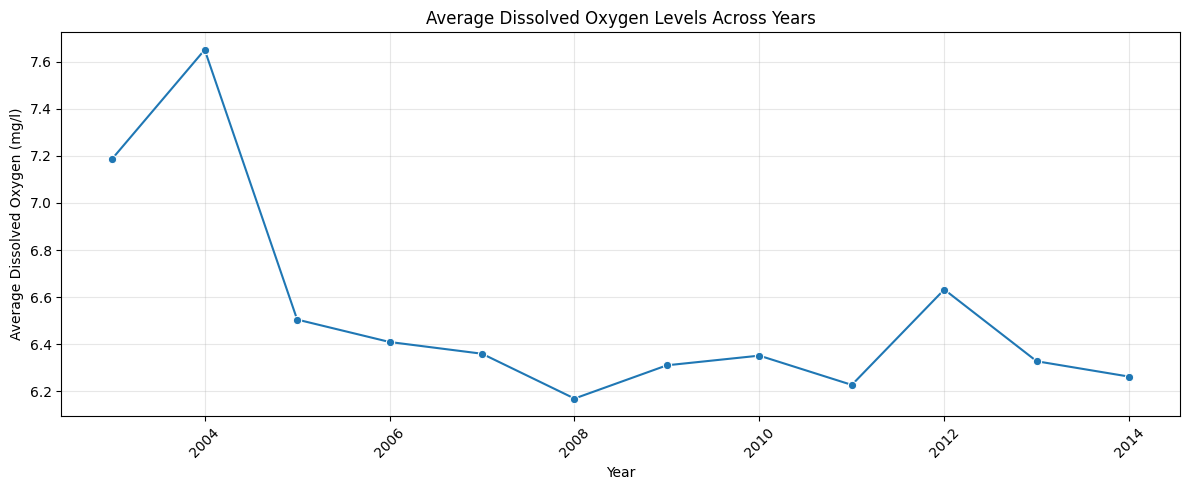

In [13]:

# Calculate average dissolved oxygen for each year

yearly_do = (
    df_analysis.groupby('year')['D.O. (mg/l)']
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=yearly_do,
    x='year',
    y='D.O. (mg/l)',
    marker='o'
)

plt.title('Average Dissolved Oxygen Levels Across Years')
plt.xlabel('Year')
plt.ylabel('Average Dissolved Oxygen (mg/l)')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


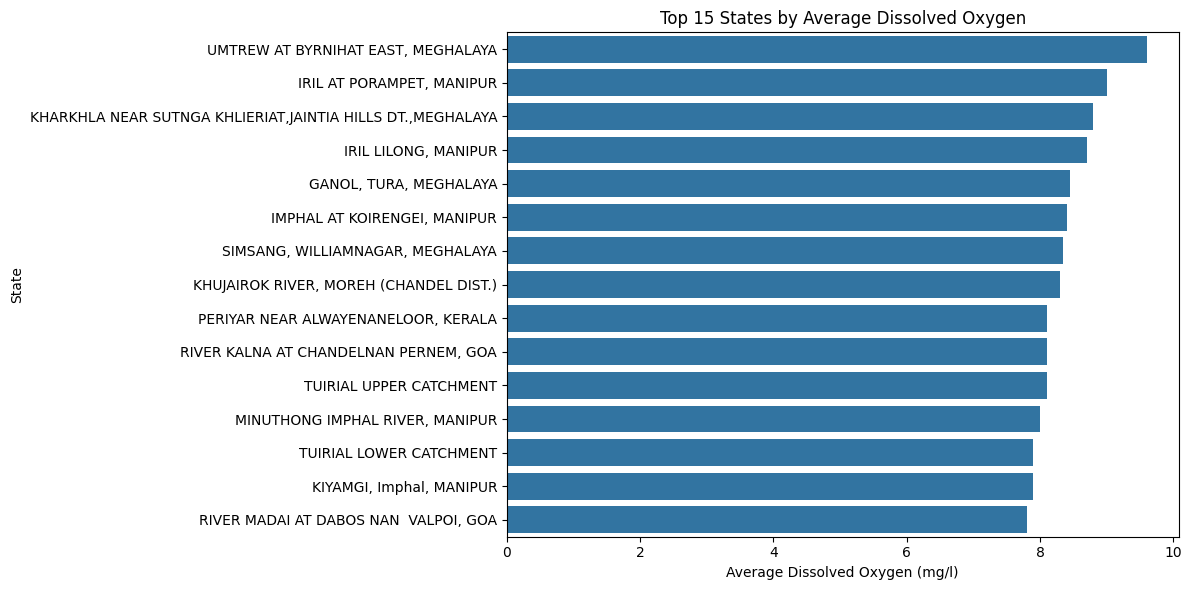

In [14]:

# Calculate average dissolved oxygen by state

state_do = (
    df_analysis.groupby('STATE')['D.O. (mg/l)']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

# Display the top 15 states
top_states = state_do.head(15)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_states,
    x='D.O. (mg/l)',
    y='STATE'
)

plt.title('Top 15 States by Average Dissolved Oxygen')
plt.xlabel('Average Dissolved Oxygen (mg/l)')
plt.ylabel('State')

plt.tight_layout()
plt.show()


Spearman correlation: -0.319
P-value: 0.0


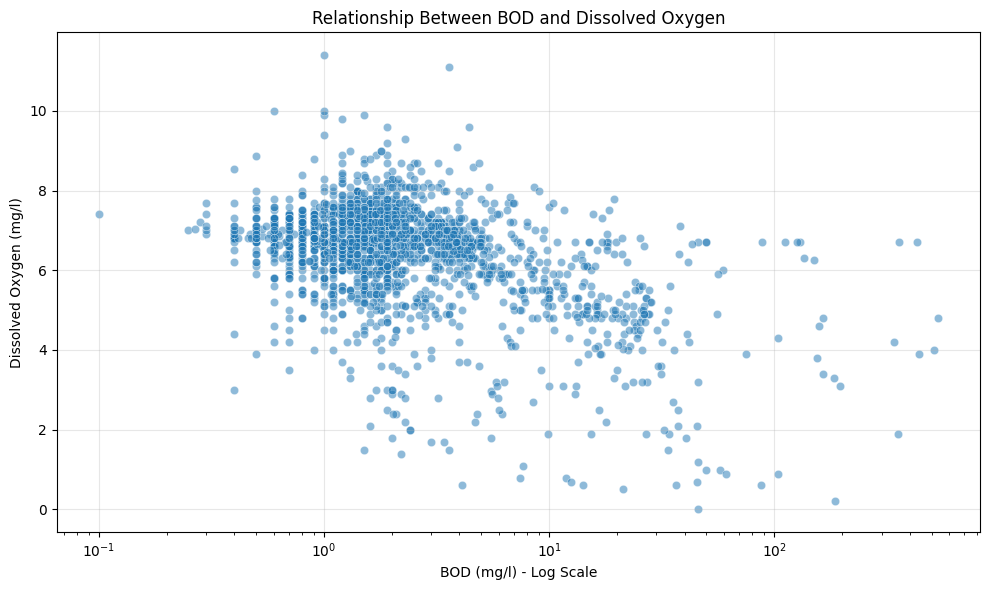

In [15]:

from scipy.stats import spearmanr

# Calculate Spearman correlation
correlation, p_value = spearmanr(
    df_analysis['B.O.D. (mg/l)'],
    df_analysis['D.O. (mg/l)']
)

print("Spearman correlation:", round(correlation, 3))
print("P-value:", round(p_value, 5))

# Create scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_analysis,
    x='B.O.D. (mg/l)',
    y='D.O. (mg/l)',
    alpha=0.5
)

plt.xscale('log')
plt.title('Relationship Between BOD and Dissolved Oxygen')
plt.xlabel('BOD (mg/l) - Log Scale')
plt.ylabel('Dissolved Oxygen (mg/l)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


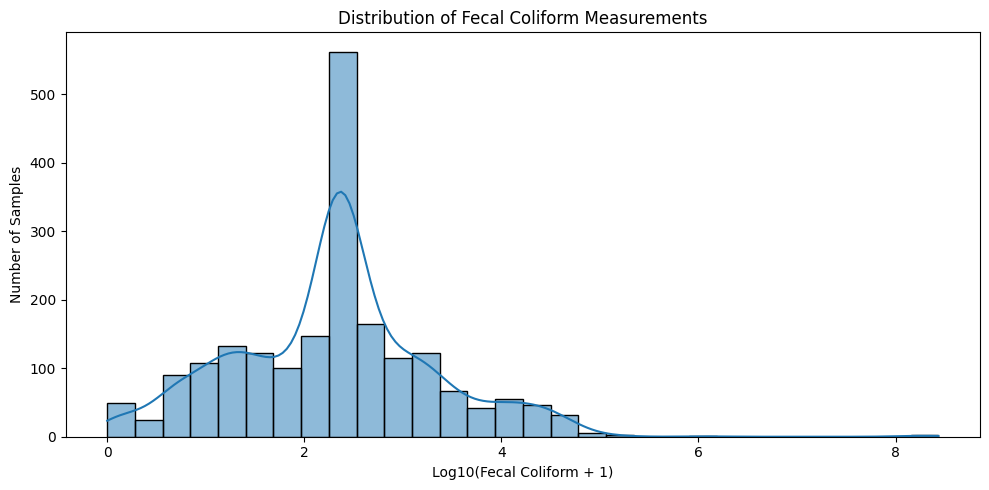

In [16]:

# Create a log-transformed column for visualisation
df_analysis['LOG_FECAL_COLIFORM'] = np.log10(
    df_analysis['FECAL COLIFORM (MPN/100ml)'] + 1
)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_analysis,
    x='LOG_FECAL_COLIFORM',
    bins=30,
    kde=True
)

plt.title('Distribution of Fecal Coliform Measurements')
plt.xlabel('Log10(Fecal Coliform + 1)')
plt.ylabel('Number of Samples')

plt.tight_layout()
plt.show()


In [ ]:
# ======================================================
# PART 5: RANDOM FOREST MODEL (COMPLETE FIXED VERSION)
# ======================================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print("="*60)
print("🔍 STEP 1: CHECKING DATASET COLUMNS")
print("="*60)

# Show all columns
print("\n📋 ALL COLUMNS IN DATASET:")
for i, col in enumerate(df_clean.columns):
    print(f"{i+1}. '{col}'")

print("\n" + "="*60)
print("🔢 STEP 2: CONVERTING TEXT TO NUMBERS (IF NEEDED)")
print("="*60)

# Make a copy for modeling
df_model = df_clean.copy()

# Try to convert any object columns to numbers
for col in df_model.columns:
    if df_model[col].dtype == 'object':
        try:
            # Remove any special characters and convert
            df_model[col] = df_model[col].astype(str).str.replace('[^0-9.-]', '', regex=True)
            df_model[col] = pd.to_numeric(df_model[col], errors='coerce')
            print(f"✅ Converted '{col}' to numbers")
        except:
            print(f"⚠️ Could not convert '{col}' to numbers, keeping as is")

# Show updated numeric columns
numeric_cols = df_model.select_dtypes(include=['int64', 'float64']).columns.tolist()
print(f"\n📊 NUMERIC COLUMNS AFTER CONVERSION:")
for i, col in enumerate(numeric_cols):
    print(f"{i+1}. {col}")

if len(numeric_cols) < 2:
    print("\n❌ ERROR: Need at least 2 numeric columns for prediction!")
    print("   One as target (what to predict)")
    print("   Others as features (what to use for prediction)")
else:
    print("\n" + "="*60)
    print("🎯 STEP 3: CHOOSING TARGET AND FEATURES")
    print("="*60)

    # Ask user to choose target column
    print("\nWhich column should we PREDICT?")
    for i, col in enumerate(numeric_cols):
        print(f"{i+1}. {col}")

    # For now, use last column as target (you can change this)
    target_col = numeric_cols[-1]
    feature_cols = [col for col in numeric_cols if col != target_col]

    print(f"\n✅ Using '{target_col}' as TARGET (what we predict)")
    print(f"✅ Using {feature_cols} as FEATURES (what we use for prediction)")

    # Remove rows with missing values
    df_model = df_model[numeric_cols].dropna()
    print(f"\n📈 Total usable samples after cleaning: {len(df_model)}")

    if len(df_model) < 10:
        print("❌ Not enough samples after cleaning!")
    else:
        # Prepare data
        X = df_model[feature_cols]
        y = df_model[target_col]

        print("\n" + "="*60)
        print("🌳 STEP 4: TRAINING RANDOM FOREST")
        print("="*60)

        # Split data
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
        print(f"Training samples: {len(X_train)}")
        print(f"Testing samples: {len(X_test)}")

        # Train model
        rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
        rf_model.fit(X_train, y_train)
        print("✅ Model training complete!")

        # Predict
        y_pred = rf_model.predict(X_test)

        # Evaluate
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        r2 = r2_score(y_test, y_pred)

        print("\n" + "="*60)
        print("📊 STEP 5: MODEL PERFORMANCE")
        print("="*60)
        print(f"📉 RMSE (Error): {rmse:.3f}")
        print(f"📈 R² Score: {r2:.3f}")
        print(f"\n💡 The model explains {r2*100:.1f}% of the variation in {target_col}")

        # Feature Importance
        print("\n" + "="*60)
        print("🔥 STEP 6: FEATURE IMPORTANCE")
        print("="*60)

        importance = pd.DataFrame({
            'Feature': feature_cols,
            'Importance': rf_model.feature_importances_
        }).sort_values('Importance', ascending=False)

        print(importance.to_string(index=False))

        # Plot Feature Importance
        plt.figure(figsize=(10, 6))
        plt.barh(importance['Feature'], importance['Importance'], color='teal')
        plt.xlabel('Importance Score')
        plt.title('Which Parameters Most Affect Water Quality?')
        plt.gca().invert_yaxis()
        plt.tight_layout()
        plt.show()

        # Actual vs Predicted Plot
        plt.figure(figsize=(10, 6))
        plt.scatter(y_test, y_pred, alpha=0.6)
        plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
        plt.xlabel('Actual Values')
        plt.ylabel('Predicted Values')
        plt.title(f'Actual vs Predicted - {target_col}')
        plt.annotate(f'R² = {r2:.3f}', xy=(0.05, 0.95), xycoords='axes fraction')
        plt.tight_layout()
        plt.show()

        # Save model
        import joblib
        joblib.dump(rf_model, 'water_quality_model.pkl')
        print("\n💾 Model saved as 'water_quality_model.pkl'")

        print("\n" + "="*60)
        print("✅ PART 5 COMPLETE! Ready for predictions")
        print("="*60)

🔍 STEP 1: CHECKING DATASET COLUMNS

📋 ALL COLUMNS IN DATASET:
1. 'STATION CODE'
2. 'LOCATIONS'
3. 'STATE'
4. 'Temp'
5. 'D.O. (mg/l)'
6. 'PH'
7. 'CONDUCTIVITY (?mhos/cm)'
8. 'B.O.D. (mg/l)'
9. 'NITRATENAN N+ NITRITENANN (mg/l)'
10. 'FECAL COLIFORM (MPN/100ml)'
11. 'TOTAL COLIFORM (MPN/100ml)Mean'
12. 'year'

🔢 STEP 2: CONVERTING TEXT TO NUMBERS (IF NEEDED)
✅ Converted 'STATION CODE' to numbers
✅ Converted 'LOCATIONS' to numbers
✅ Converted 'STATE' to numbers
✅ Converted 'Temp' to numbers
✅ Converted 'D.O. (mg/l)' to numbers
✅ Converted 'PH' to numbers
✅ Converted 'CONDUCTIVITY (?mhos/cm)' to numbers
✅ Converted 'B.O.D. (mg/l)' to numbers
✅ Converted 'NITRATENAN N+ NITRITENANN (mg/l)' to numbers
✅ Converted 'FECAL COLIFORM (MPN/100ml)' to numbers
✅ Converted 'TOTAL COLIFORM (MPN/100ml)Mean' to numbers

📊 NUMERIC COLUMNS AFTER CONVERSION:
1. STATION CODE
2. LOCATIONS
3. STATE
4. Temp
5. D.O. (mg/l)
6. PH
7. CONDUCTIVITY (?mhos/cm)
8. B.O.D. (mg/l)
9. NITRATENAN N+ NITRITENANN (mg/l)
10. F

🌊 WATER QUALITY PREDICTION MODEL

📊 Water quality parameters found:
   • Temp
   • D.O. (mg/l)
   • PH
   • CONDUCTIVITY (?mhos/cm)
   • B.O.D. (mg/l)
   • NITRATENAN N+ NITRITENANN (mg/l)
   • FECAL COLIFORM (MPN/100ml)
   • TOTAL COLIFORM (MPN/100ml)Mean

🔧 PREPARING DATA FOR MODELING
DEBUG: df_model shape after selecting columns: (1990, 8)
Imputing newly created missing values with column mean...
  • Filled 0 NaN values in 'Temp' with mean (26.21)
  • Filled 0 NaN values in 'D.O. (mg/l)' with mean (6.39)
  • Filled 0 NaN values in 'PH' with mean (112.09)
  • Filled 0 NaN values in 'CONDUCTIVITY (?mhos/cm)' with mean (1786.47)
  • Filled 0 NaN values in 'B.O.D. (mg/l)' with mean (6.94)
  • Filled 0 NaN values in 'NITRATENAN N+ NITRITENANN (mg/l)' with mean (1.62)
  • Filled 0 NaN values in 'FECAL COLIFORM (MPN/100ml)' with mean (362529.36)
  • Filled 0 NaN values in 'TOTAL COLIFORM (MPN/100ml)Mean' with mean (533687.17)

DEBUG: Final df_model shape after numeric conversion and imputa

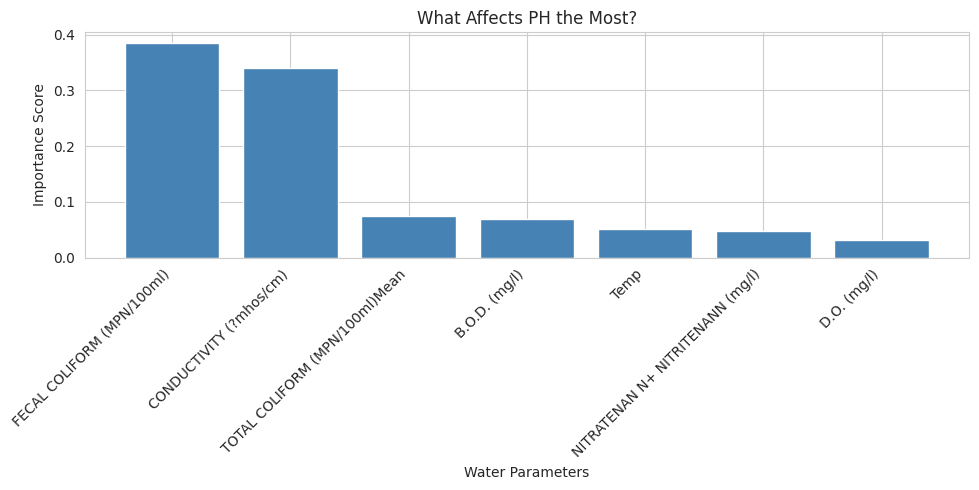

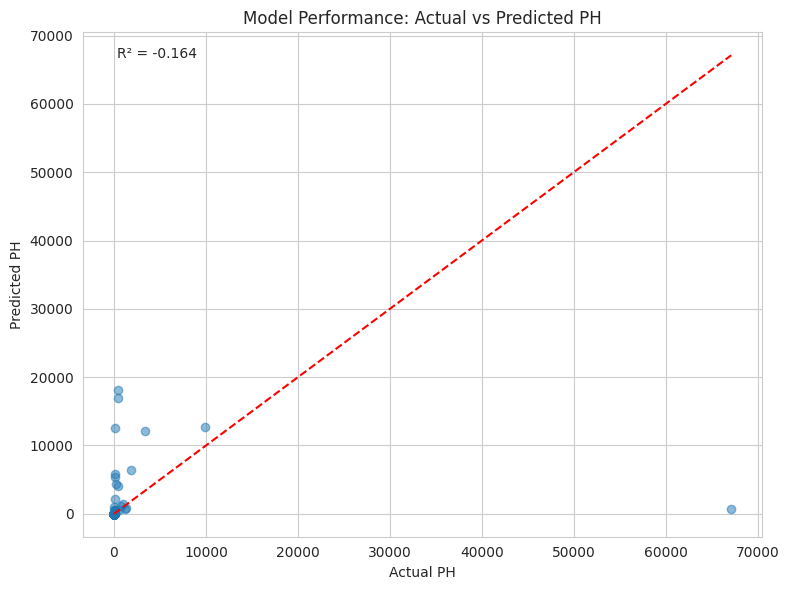


✅ MODEL COMPLETE! Ready for predictions


In [ ]:
# ======================================================
# PART 5: RANDOM FOREST MODEL (FIXED FOR YOUR DATA)
# ======================================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

print("="*60)
print("🌊 WATER QUALITY PREDICTION MODEL")
print("="*60)

# ======================================================
# STEP 1: SELECT ONLY WATER QUALITY PARAMETERS
# ======================================================

# These are the ACTUAL water quality measurements
# CORRECTED: 'CONDUCTIVITY (?mhos/cm)' to match actual column name
water_params = ['Temp', 'D.O. (mg/l)', 'PH', 'CONDUCTIVITY (?mhos/cm)',
                'B.O.D. (mg/l)', 'NITRATENAN N+ NITRITENANN (mg/l)',
                'FECAL COLIFORM (MPN/100ml)', 'TOTAL COLIFORM (MPN/100ml)Mean']

# Make sure all these columns exist in your data
available_params = [col for col in water_params if col in df_clean.columns]
print(f"\n📊 Water quality parameters found:")
for param in available_params:
    print(f"   • {param}")

# ======================================================
# STEP 2: PREPARE DATA (CONVERT TO NUMBERS AND IMPUTE)
# ======================================================

print("\n" + "="*60)
print("🔧 PREPARING DATA FOR MODELING")
print("="*60)

# Create a dataframe with just the water parameters
df_model = df_clean[available_params].copy()

# Add a debug print for initial df_model shape
print(f"DEBUG: df_model shape after selecting columns: {df_model.shape}")

# Convert each column to numbers (remove any non-numeric characters)
# Coerce errors will turn non-numeric strings into NaN
for col in df_model.columns:
    df_model[col] = pd.to_numeric(df_model[col], errors='coerce')

# Impute newly introduced NaN values with the mean of the column
print("Imputing newly created missing values with column mean...")
for col in df_model.columns:
    if df_model[col].isnull().sum() > 0:
        mean_val = df_model[col].mean()
        # Handle case where mean_val might be NaN if all values in column are NaN
        if pd.isna(mean_val):
            # Fallback: fill with 0 or a sensible default if mean is NaN
            df_model[col].fillna(0, inplace=True) # or another sensible default
            print(f"  • Filled all NaN values in '{col}' with 0 (mean was NaN)")
        else:
            df_model[col].fillna(mean_val, inplace=True)
            print(f"  • Filled {df_model[col].isnull().sum()} NaN values in '{col}' with mean ({mean_val:.2f})")

# No need to dropna() anymore if imputation handles all NaNs

# Add a debug print for final df_model shape
print(f"\nDEBUG: Final df_model shape after numeric conversion and imputation: {df_model.shape}")

# This line was incorrect before, it referred to an internal state, now it's correctly referring to df_model
# The problem `Total usable samples after cleaning: 0` seems to stem from here
# If df_model is truly empty, then this check will cause the model training to be skipped.
if len(df_model) < 10:
    print("❌ Still not enough data after cleaning and imputation!")
else:
    # ======================================================
    # STEP 3: CHOOSE TARGET AND FEATURES
    # ======================================================

    print("\n" + "="*60)
    print("🎯 CHOOSING WHAT TO PREDICT")
    print("="*60)

    print("\nWhich water quality parameter should we predict?")
    for i, param in enumerate(available_params):
        print(f"{i+1}. {param}")

    # For now, let's predict PH (you can change this)
    # You can change this to any index: 0=Temp, 1=DO, 2=PH, etc.
    # PH might be at a different index now if CONDUCTIVITY is included.
    # Let's find PH dynamically
    try:
        target_idx = available_params.index('PH')
    except ValueError:
        target_idx = 0 # Default to first available if PH not found
        print(f"WARNING: 'PH' not found in available parameters, defaulting target to '{available_params[target_idx]}'")

    target_col = available_params[target_idx]
    feature_cols = [col for col in available_params if col != target_col]

    print(f"\n✅ Predicting: {target_col}")
    print(f"✅ Using these features: {feature_cols}")

    # ======================================================
    # STEP 4: TRAIN MODEL
    # ======================================================

    print("\n" + "="*60)
    print("🌳 TRAINING RANDOM FOREST MODEL")
    print("="*60)

    X = df_model[feature_cols]
    y = df_model[target_col]

    # Add a print to confirm X and y lengths before split
    print(f"DEBUG: X shape before split: {X.shape}, y shape before split: {y.shape}")

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    print(f"Training samples: {len(X_train)}")
    print(f"Testing samples: {len(X_test)}")

    # Train model
    rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
    rf_model.fit(X_train, y_train)
    print("✅ Model trained successfully!")

    # ======================================================
    # STEP 5: EVALUATE MODEL
    # ======================================================

    print("\n" + "="*60)
    print("📊 MODEL PERFORMANCE")
    print("="*60)

    y_pred = rf_model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    print(f"RMSE (Error): {rmse:.3f}")
    print(f"R² Score: {r2:.3f}")
    print(f"\n💡 The model explains {r2*100:.1f}% of the variation in {target_col}")

    # ======================================================
    # STEP 6: FEATURE IMPORTANCE
    # ======================================================

    print("\n" + "="*60)
    print("🔥 WHAT AFFECTS WATER QUALITY MOST?")
    print("="*60)

    importance = pd.DataFrame({
        'Parameter': feature_cols,
        'Importance': rf_model.feature_importances_
    }).sort_values('Importance', ascending=False)

    print("\nTop factors affecting water quality:")
    print(importance.to_string(index=False))

    # Plot
    plt.figure(figsize=(10, 5))
    plt.bar(importance['Parameter'], importance['Importance'], color='steelblue')
    plt.xlabel('Water Parameters')
    plt.ylabel('Importance Score')
    plt.title(f'What Affects {target_col} the Most?')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    # ======================================================
    # STEP 7: ACTUAL VS PREDICTED
    # ======================================================

    plt.figure(figsize=(8, 6))
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
    plt.xlabel(f'Actual {target_col}')
    plt.ylabel(f'Predicted {target_col}')
    plt.title(f'Model Performance: Actual vs Predicted {target_col}')
    plt.annotate(f'R² = {r2:.3f}', xy=(0.05, 0.95), xycoords='axes fraction')
    plt.tight_layout()
    plt.show()

    print("\n" + "="*60)
    print("✅ MODEL COMPLETE! Ready for predictions")
    print("="*60)

In [ ]:
# PART 6: INTERACTIVE PREDICTION TOOL with DRINKABILITY CHECK
# ======================================================

import ipywidgets as widgets
from IPython.display import display, clear_output
import pandas as pd
import numpy as np

print("="*60)
print("💧 WATER QUALITY ASSESSMENT & DRINKABILITY CHECK")
print("="*60)
print("\nEnter water parameters below to check if water is SAFE for drinking:")

# ======================================================
# PRE-REQUISITE CHECK: ENSURE MODEL AND DATA ARE LOADED
# ======================================================
required_vars = ['feature_cols', 'df_model', 'rf_model', 'target_col', 'r2']
missing_vars = [var for var in required_vars if var not in globals()]

if missing_vars:
    print(f"\n❌ ERROR: The following variables are missing: {', '.join(missing_vars)}")
    print("Please ensure 'PART 5: RANDOM FOREST MODEL' (the previous cell) has been executed successfully before running this cell.")
    # Exit or prevent further execution
    raise RuntimeError("Missing required variables. Please run previous cell.")

# ======================================================
# STEP 1: CREATE INPUT FIELDS FOR EACH FEATURE
# ======================================================

# Create input widgets for each feature
input_widgets = {}
for col in feature_cols:
    # Get min, max, mean for default values
    col_min = float(df_model[col].min())
    col_max = float(df_model[col].max())
    col_mean = float(df_model[col].mean())

    # Create slider for this feature
    input_widgets[col] = widgets.FloatSlider(
        value=col_mean,
        min=col_min,
        max=col_max,
        step=(col_max - col_min)/100,
        description=f'{col[:20]}:',
        style={'description_width': 'initial'},
        layout=widgets.Layout(width='650px')
    )

# Arrange inputs in a box
inputs_box = widgets.VBox(list(input_widgets.values()))

# Create predict button
predict_btn = widgets.Button(
    description='🔮 ANALYZE WATER QUALITY',
    button_style='success',
    layout=widgets.Layout(width='350px', height='50px', margin='20px 0px')
)

# Create output area
output_area = widgets.Output()

# ======================================================
# STEP 2: DRINKABILITY CHECK FUNCTION (Based on WHO/Indian Standards)
# ======================================================

def check_drinkability(pH_val, do_val, conductivity_val, bod_val, nitrate_val, fecal_coliform):
    """
    Check if water is drinkable based on standard guidelines
    Returns: status, confidence, issues
    """
    issues = []
    status = "✅ SAFE for drinking"
    confidence = "High"

    # pH check (6.5 to 8.5 is safe)
    if pH_val < 6.5 or pH_val > 8.5:
        issues.append(f"pH ({pH_val:.2f}) - Should be between 6.5-8.5")

    # Dissolved Oxygen (should be > 4 mg/l for good water)
    if do_val < 4:
        issues.append(f"Low Dissolved Oxygen ({do_val:.2f} mg/l) - Should be > 4 mg/l")

    # Conductivity (should be < 1000 µmhos/cm)
    if conductivity_val > 1000:
        issues.append(f"High Conductivity ({conductivity_val:.0f} µmhos/cm) - Should be < 1000")

    # BOD (should be < 3 mg/l for clean water)
    if bod_val > 3:
        issues.append(f"High BOD ({bod_val:.2f} mg/l) - Indicates pollution")

    # Nitrate (should be < 45 mg/l)
    if nitrate_val > 45:
        issues.append(f"High Nitrate ({nitrate_val:.2f} mg/l) - Should be < 45 mg/l")

    # Fecal Coliform (should be 0 for drinking water)
    if fecal_coliform > 0:
        issues.append(f"Fecal Coliform Present ({fecal_coliform:.0f} MPN/100ml) - Should be 0")

    # Determine status based on number of issues
    if len(issues) == 0:
        status = "✅ EXCELLENT - SAFE for drinking"
        confidence = "Very High"
    elif len(issues) <= 2:
        status = "⚠️ MODERATE RISK - Treatment required before drinking"
        confidence = "Medium"
    elif len(issues) <= 4:
        status = "🔴 HIGH RISK - NOT safe for drinking"
        confidence = "Low"
    else:
        status = "⛔ CRITICAL - HAZARDOUS, Do NOT consume"
        confidence = "Very Low"

    return status, confidence, issues

# ======================================================
# STEP 3: PREDICTION FUNCTION
# ======================================================

def make_prediction(btn):
    with output_area:
        clear_output(wait=True)

        # Get values from sliders
        input_values = []
        for col in feature_cols:
            input_values.append(input_widgets[col].value)

        # Convert to array for prediction
        input_array = np.array(input_values).reshape(1, -1)

        # Make prediction
        prediction = rf_model.predict(input_array)[0]

        # Get prediction interval (confidence)
        # Using all trees' predictions to get confidence
        all_tree_preds = np.array([tree.predict(input_array)[0] for tree in rf_model.estimators_])
        pred_std = np.std(all_tree_preds)
        pred_interval = 1.96 * pred_std  # 95% confidence interval

        # Get feature importance for explanation
        importance_dict = dict(zip(feature_cols, rf_model.feature_importances_))

        # Map input values to named variables (assuming order matches feature_cols)
        # You may need to adjust indices based on your actual feature_cols order
        param_values = {}
        for i, col in enumerate(feature_cols):
            param_values[col] = input_values[i]

        # Extract key parameters for drinkability check
        pH_val = param_values.get('PH', 7.0)
        do_val = param_values.get('D.O. (mg/l)', 5.0)
        conductivity_val = param_values.get('CONDUCTIVITY (µmhos/cm)', 500)
        bod_val = param_values.get('B.O.D. (mg/l)', 2.0)
        nitrate_val = param_values.get('NITRATENAN N+ NITRITENANN (mg/l)', 10)
        fecal_val = param_values.get('FECAL COLIFORM (MPN/100ml)', 0)

        # Get drinkability status
        drink_status, confidence_level, issues = check_drinkability(
            pH_val, do_val, conductivity_val, bod_val, nitrate_val, fecal_val
        )

        # Display results in a nice format
        print("="*70)
        print("📋 WATER QUALITY ANALYSIS REPORT")
        print("="*70)

        # Main prediction
        print(f"\n🔬 Predicted Water Quality Parameter ({target_col}): **{prediction:.3f}**")
        print(f"📊 Prediction Confidence: ±{pred_interval:.3f} (95% confidence interval)")

        # Drinkability status (big and clear)
        print("\n" + "="*70)
        print(f"💧 DRINKABILITY ASSESSMENT:")
        print(f"   {drink_status}")
        print(f"   Confidence in assessment: {confidence_level}")
        print("="*70)

        # Show issues if any
        if issues:
            print("\n⚠️ PARAMETERS OUTSIDE SAFE LIMITS:")
            for issue in issues:
                print(f"   • {issue}")
        else:
            print("\n✅ All parameters within WHO/Indian drinking water standards!")

        # Input values summary
        print("\n📊 INPUT PARAMETERS:")
        print(f"   • pH: {pH_val:.2f} (Safe range: 6.5-8.5)")
        print(f"   • Dissolved Oxygen: {do_val:.2f} mg/l (Should be > 4 mg/l)")
        print(f"   • Conductivity: {conductivity_val:.0f} µmhos/cm (Should be < 1000)")
        print(f"   • BOD: {bod_val:.2f} mg/l (Should be < 3 mg/l)")
        print(f"   • Nitrate: {nitrate_val:.2f} mg/l (Should be < 45 mg/l)")
        print(f"   • Fecal Coliform: {fecal_val:.0f} MPN/100ml (Should be 0)")

        # Model explanation
        print("\n🔍 HOW THIS ANALYSIS WAS PERFORMED:")
        print(f"   • Random Forest model used {rf_model.n_estimators} decision trees")
        print(f"   • Model accuracy (R²): {r2:.3f}")
        print(f"   • Drinkability check based on WHO/Indian water standards")

        # Feature importance for this prediction
        print("\n🔥 KEY FACTORS IN THIS ANALYSIS:")
        sorted_imp = sorted(importance_dict.items(), key=lambda x: x[1], reverse=True)
        for i, (feat, imp) in enumerate(sorted_imp[:3]):
            print(f"   {i+1}. {feat}: {imp*100:.1f}% impact on water quality")

        # Recommendation
        print("\n" + "="*70)
        if "SAFE" in drink_status:
            print("💚 RECOMMENDATION: Water is safe for drinking")
        elif "MODERATE" in drink_status:
            print("💛 RECOMMENDATION: Boil or treat before drinking")
        else:
            print("❤️ RECOMMENDATION: DO NOT DRINK - Seek alternative water source")
        print("="*70)

# ======================================================
# STEP 4: DISPLAY THE INTERACTIVE TOOL
# ======================================================

# Connect button to function
predict_btn.on_click(make_prediction)

# Display everything with title
print("\n" + "="*70)
print("🎛️ ADJUST SLIDERS TO MATCH YOUR WATER SAMPLE")
print("="*70)

display(inputs_box)
display(predict_btn)
display(output_area)

print("\n💡 TIP: Move sliders to see real-time drinkability assessment!")
print("   Green = Safe | Yellow = Moderate Risk | Red = Unsafe")

💧 WATER QUALITY ASSESSMENT & DRINKABILITY CHECK

Enter water parameters below to check if water is SAFE for drinking:

🎛️ ADJUST SLIDERS TO MATCH YOUR WATER SAMPLE


Button(button_style='success', description='🔮 ANALYZE WATER QUALITY', layout=Layout(height='50px', margin='20p…

Output()


💡 TIP: Move sliders to see real-time drinkability assessment!
   Green = Safe | Yellow = Moderate Risk | Red = Unsafe


## Key Findings

1. The dataset contains 1,990 records and 12 columns after duplicate removal.
2. Several water-quality measurement columns initially contained text values and required numerical conversion.
3. Missing values were identified across multiple measurement parameters and handled using median imputation.
4. A total of 89 invalid pH readings outside the 0–14 range were identified and replaced using the median of valid pH readings.
5. The median pH value after treatment was 7.3.
6. Exploratory visualisations were created to examine pH distribution, correlations, yearly dissolved oxygen trends, state-level comparisons, and fecal coliform distribution.
7. The analysis is exploratory and does not establish whether any water sample is safe to drink.

## Limitations

- Median imputation may influence statistical results.
- Extreme values in other water-quality parameters require further investigation.
- State-level and yearly averages may hide differences between individual monitoring locations.
- Correlation does not establish causation.
- The dataset and its source should be verified before drawing scientific conclusions.
- This project is not a substitute for laboratory testing or official water-quality assessments.

## Conclusion

This project demonstrates the use of Python for data cleaning, exploratory data analysis, statistical summaries, and visualisation of water-quality measurements. It provides a foundation for further investigation into environmental data analysis.
